## 1. Resample and Clean SCADA Data
The SCADA data has high-frequency, irregular timestamps. 

Filter invalid records (e.g., based on running_status_code)

Resample to 15-minute intervals (matching NWP)

In [1]:
import pandas as pd
import numpy as np

# Load SCADA data
scada = pd.read_csv("../../data/raw/turbine_1_cleaned.csv", parse_dates=["Time"])
scada = scada.rename(columns={"Time": "time", "wind_spped": "wind_speed"})
scada = scada.sort_values("time")

# Optional: Filter valid operational data
valid_codes = [3.0]  # adjust based on actual status code
scada = scada[scada["running_status_code"].isin(valid_codes)]

# Resample to 15-min intervals using mean
scada.set_index("time", inplace=True)
scada.index = scada.index.floor('S')
scada_15min = scada.resample("15T").mean().dropna().reset_index()

C:\Users\Lucas\AppData\Local\Temp\ipykernel_12144\1655270811.py:15: FutureWarning: 'S' is deprecated and will be removed in a future version, please use 's' instead.
  scada.index = scada.index.floor('S')
C:\Users\Lucas\AppData\Local\Temp\ipykernel_12144\1655270811.py:16: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  scada_15min = scada.resample("15T").mean().dropna().reset_index()


In [2]:
scada_15min

,time,paddle2_angle,power,outdoor_temp,wind_speed,cabin_angle,paddle1_angle,total_cabin_angle,paddle3_angle,running_status_code,wind_direction
0,2022-10-15 09:45:00,0.0,691.771084,23.433735,6.336145,46.661446,0.0,46.855422,0.0,3.0,5.538554
1,2022-10-15 10:00:00,0.0,583.102273,23.332954,6.082955,35.356818,0.0,35.397727,0.0,3.0,2.852273
2,2022-10-15 10:15:00,0.0,507.577778,23.264444,5.941111,43.107779,0.0,43.133333,0.0,3.0,6.680000
3,2022-10-15 10:30:00,0.0,552.566667,23.214445,6.015556,49.900002,0.0,50.000000,0.0,3.0,-0.823333
4,2022-10-15 10:45:00,0.0,701.977778,23.305555,6.130000,55.833334,0.0,55.588889,0.0,3.0,1.073333
...,...,...,...,...,...,...,...,...,...,...,...
44069,2024-12-05 05:30:00,0.0,252.000000,16.200001,4.500000,62.000000,0.0,62.000000,0.0,3.0,-30.000000
44070,2024-12-05 05:45:00,0.0,252.000000,16.200001,4.500000,62.000000,0.0,62.000000,0.0,3.0,-30.000000
44071,2024-12-05 06:00:00,0.0,160.324324,16.118147,4.008880,60.403860,0.0,60.362934,0.0,3.0,-22.919691
44072,2024-12-05 06:15:00,0.0,28.000000,16.000000,3.300000,58.099998,0.0,58.000000,0.0,3.0,-12.700000


In [3]:
scada

,paddle2_angle,power,outdoor_temp,wind_speed,cabin_angle,paddle1_angle,total_cabin_angle,paddle3_angle,running_status_code,wind_direction
time,,,,,,,,,,
2022-10-15 09:45:03,0.0,1085.0,23.5,7.1,49.400002,0.0,49.0,0.0,3.0,14.8
2022-10-15 09:45:13,0.0,1085.0,23.5,7.1,49.400002,0.0,49.0,0.0,3.0,14.8
2022-10-15 09:45:22,0.0,1110.0,23.5,7.3,49.400002,0.0,49.0,0.0,3.0,12.0
2022-10-15 09:45:32,0.0,1110.0,23.5,7.3,49.400002,0.0,49.0,0.0,3.0,12.0
2022-10-15 09:45:42,0.0,1109.0,23.5,6.3,49.400002,0.0,49.0,0.0,3.0,-12.7
...,...,...,...,...,...,...,...,...,...,...
2024-12-05 06:38:06,0.0,28.0,16.0,3.3,58.099998,0.0,58.0,0.0,3.0,-12.7
2024-12-05 06:38:06,0.0,28.0,16.0,3.3,58.099998,0.0,58.0,0.0,3.0,-12.7
2024-12-05 06:38:06,0.0,28.0,16.0,3.3,58.099998,0.0,58.0,0.0,3.0,-12.7


## 2. Load and Align NWP Data
Load the NWP data and ensure it’s in datetime format.

In [4]:
nwp = pd.read_csv("../../data/raw/nwp_cleaned.csv", parse_dates=["Time"])  # use actual column name
nwp = nwp.rename(columns={"Time": "time"})
nwp = nwp.sort_values("time")

In [5]:
nwp

,time,air_pressure,wind_direction_100m,wind_speed_100m,temperature,air_density
0,2022-10-15 09:45:00,999.1650,38.0424,6.4409,26.675,1.072333
1,2022-10-15 10:00:00,999.2900,39.0029,6.3651,26.500,1.072159
2,2022-10-15 10:15:00,999.3925,40.0542,6.2972,26.300,1.072086
3,2022-10-15 10:30:00,999.4950,41.1054,6.2292,26.100,1.072011
4,2022-10-15 10:45:00,999.5975,42.1567,6.1612,25.900,1.071935
...,...,...,...,...,...,...
94581,2025-06-26 15:00:00,961.1000,201.9943,1.8041,23.900,NaN
94582,2025-06-26 15:15:00,960.9600,202.9124,1.7772,23.850,NaN
94583,2025-06-26 15:30:00,960.8200,203.8305,1.7504,23.800,NaN
94584,2025-06-26 15:45:00,960.6800,204.7485,1.7235,23.750,NaN


## 3. Merge SCADA + NWP by Timestamp
Use an inner join on 15-min timestamps. Ensure both timestamps are aligned precisely.

In [6]:
# Align timestamps to exact 15-min resolution
scada_15min["time"] = scada_15min["time"].dt.floor("15T")
nwp["time"] = nwp["time"].dt.floor("15T")

# Merge on time
df = pd.merge(scada_15min, nwp, how="inner", on="time")
print(df.shape)

(44074, 16)


C:\Users\Lucas\AppData\Local\Temp\ipykernel_12144\2790245946.py:2: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  scada_15min["time"] = scada_15min["time"].dt.floor("15T")
C:\Users\Lucas\AppData\Local\Temp\ipykernel_12144\2790245946.py:3: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  nwp["time"] = nwp["time"].dt.floor("15T")


In [7]:
df

,time,paddle2_angle,power,outdoor_temp,wind_speed,cabin_angle,paddle1_angle,total_cabin_angle,paddle3_angle,running_status_code,wind_direction,air_pressure,wind_direction_100m,wind_speed_100m,temperature,air_density
0,2022-10-15 09:45:00,0.0,691.771084,23.433735,6.336145,46.661446,0.0,46.855422,0.0,3.0,5.538554,999.1650,38.0424,6.4409,26.675,1.072333
1,2022-10-15 10:00:00,0.0,583.102273,23.332954,6.082955,35.356818,0.0,35.397727,0.0,3.0,2.852273,999.2900,39.0029,6.3651,26.500,1.072159
2,2022-10-15 10:15:00,0.0,507.577778,23.264444,5.941111,43.107779,0.0,43.133333,0.0,3.0,6.680000,999.3925,40.0542,6.2972,26.300,1.072086
3,2022-10-15 10:30:00,0.0,552.566667,23.214445,6.015556,49.900002,0.0,50.000000,0.0,3.0,-0.823333,999.4950,41.1054,6.2292,26.100,1.072011
4,2022-10-15 10:45:00,0.0,701.977778,23.305555,6.130000,55.833334,0.0,55.588889,0.0,3.0,1.073333,999.5975,42.1567,6.1612,25.900,1.071935
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44069,2024-12-05 05:30:00,0.0,252.000000,16.200001,4.500000,62.000000,0.0,62.000000,0.0,3.0,-30.000000,940.3550,61.7392,3.6995,19.300,1.170297
44070,2024-12-05 05:45:00,0.0,252.000000,16.200001,4.500000,62.000000,0.0,62.000000,0.0,3.0,-30.000000,940.1725,63.6635,3.7014,19.350,1.169489
44071,2024-12-05 06:00:00,0.0,160.324324,16.118147,4.008880,60.403860,0.0,60.362934,0.0,3.0,-22.919691,939.9900,65.5879,3.7033,19.400,1.168681
44072,2024-12-05 06:15:00,0.0,28.000000,16.000000,3.300000,58.099998,0.0,58.000000,0.0,3.0,-12.700000,939.9975,67.6869,3.7110,19.200,1.170238


## 4. Feature Engineering
Add time-based and lag features.

In [8]:
# Add time-based features
df["hour"] = df["time"].dt.hour
df["dayofweek"] = df["time"].dt.dayofweek
df["month"] = df["time"].dt.month

# Add lag features (for sequence models)
for lag in [1, 2, 3, 4]:  # 15-min lags (up to 1 hour)
    df[f"power_lag_{lag}"] = df["power"].shift(lag)

## 5. Prepare for Sequence Model (e.g. LSTM)
Normalize features and generate input/output sequences.

In [9]:
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset

features = [
    'wind_speed', 'wind_direction', 'cabin_angle', 'total_cabin_angle',
    'paddle1_angle', 'paddle2_angle', 'paddle3_angle', 'outdoor_temp',
    'wind_speed_100m', 'wind_direction_100m', 'temperature', 'air_pressure', 'air_density',
    'hour', 'dayofweek', 'month',
    'power_lag_1', 'power_lag_2', 'power_lag_3', 'power_lag_4'
]
target = "power"

# Drop rows with NaN
df = df.dropna()

scaler_x = StandardScaler()
scaler_y = StandardScaler()

X = scaler_x.fit_transform(df[features])
y = scaler_y.fit_transform(df[[target]])

# Custom Dataset class
class WindDataset(Dataset):
    def __init__(self, X, y, input_len=16, pred_len=4):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.input_len = input_len
        self.pred_len = pred_len

    def __len__(self):
        return len(self.X) - self.input_len - self.pred_len

    def __getitem__(self, idx):
        return (
            self.X[idx:idx+self.input_len],
            self.y[idx+self.input_len:idx+self.input_len+self.pred_len],
        )


## LSTM Forecasting Model

In [10]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# Define the LSTM-based forecasting model
class LSTMForecastModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, pred_len):
        super(LSTMForecastModel, self).__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.pred_len = pred_len

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, pred_len)  # predict multiple future steps at once

    def forward(self, x):
        # x: (batch_size, input_len, input_dim)
        out, _ = self.lstm(x)  # out: (batch_size, input_len, hidden_dim)
        last_hidden = out[:, -1, :]  # take last time step's hidden state
        prediction = self.fc(last_hidden)  # (batch_size, pred_len)
        return prediction


In [11]:
def custom_accuracy(y_true, y_pred, capacity):
    error = (y_true - y_pred) / capacity
    rmse = np.sqrt(np.mean(error ** 2))
    return 1 - rmse

In [34]:
def train_model(model, train_loader, val_loader, num_epochs, lr=1e-3, device="cuda" if torch.cuda.is_available() else "cpu"):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    val_losses = []
    val_accuracies = []

    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            output = model(X_batch)
            loss = criterion(output, y_batch.squeeze(-1))
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        avg_train_loss = total_loss / len(train_loader)
        val_loss, val_acc = evaluate_model(model, val_loader, criterion, device)
        
        train_losses.append(avg_train_loss)
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)
        
        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {total_loss:.4f} | Val Loss: {val_loss:.4f}")

    return model, train_losses, val_losses, val_accuracies


In [35]:
def evaluate_model(model, dataloader, criterion, device):
    model.eval()
    val_loss = 0.0
    y_preds = []
    y_trues = []
    
    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            output = model(X_batch)
            loss = criterion(output, y_batch.squeeze(-1))
            val_loss += loss.item()
            y_preds.append(output.cpu().numpy())
            y_trues.append(y_batch.cpu().numpy())
            
    y_preds = np.concatenate(y_preds, axis=0)
    y_trues = np.concatenate(y_trues, axis=0)

    # Squeeze if needed
    if y_preds.ndim == 3 and y_preds.shape[2] == 1:
        y_preds = y_preds.squeeze(-1)
    if y_trues.ndim == 3 and y_trues.shape[2] == 1:
        y_trues = y_trues.squeeze(-1)       
        
    # Flatten to 2D for inverse transform
    y_preds_real = scaler_y.inverse_transform(y_preds.reshape(-1, 1)).reshape(y_preds.shape)
    y_trues_real = scaler_y.inverse_transform(y_trues.reshape(-1, 1)).reshape(y_trues.shape)
    
    # Capacity can be dynamic or static
    capacity = 2000
    C = np.full_like(y_trues_real, fill_value=capacity)
    acc = custom_accuracy(y_trues_real, y_preds_real, C)
    
    print(f"Val Acc: {acc:.4f}")
    
    return val_loss / len(dataloader), acc


## Putting It Together

In [36]:
# Prepare data
from torch.utils.data import random_split

input_len = 16
pred_len = 16
batch_size = 64

dataset = WindDataset(X, y, input_len=input_len, pred_len=pred_len)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = random_split(dataset, [train_size, val_size])
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)

# Instantiate and train model
model = LSTMForecastModel(input_dim=X.shape[1], hidden_dim=128, num_layers=2, pred_len=pred_len)
trained_model, train_losses, val_losses, val_accuracies = train_model(model, train_loader, val_loader, num_epochs=20)

Val Acc: 0.8234
Epoch 1/20 | Train Loss: 212.7225 | Val Loss: 0.3870
Val Acc: 0.8309
Epoch 2/20 | Train Loss: 177.5553 | Val Loss: 0.3548
Val Acc: 0.8390
Epoch 3/20 | Train Loss: 160.8190 | Val Loss: 0.3215
Val Acc: 0.8469
Epoch 4/20 | Train Loss: 142.5648 | Val Loss: 0.2909
Val Acc: 0.8562
Epoch 5/20 | Train Loss: 125.2522 | Val Loss: 0.2563
Val Acc: 0.8648
Epoch 6/20 | Train Loss: 107.9998 | Val Loss: 0.2268
Val Acc: 0.8753
Epoch 7/20 | Train Loss: 94.7064 | Val Loss: 0.1931
Val Acc: 0.8821
Epoch 8/20 | Train Loss: 82.2891 | Val Loss: 0.1725
Val Acc: 0.8886
Epoch 9/20 | Train Loss: 73.2978 | Val Loss: 0.1539
Val Acc: 0.8937
Epoch 10/20 | Train Loss: 64.5763 | Val Loss: 0.1404
Val Acc: 0.8985
Epoch 11/20 | Train Loss: 58.2262 | Val Loss: 0.1277
Val Acc: 0.9034
Epoch 12/20 | Train Loss: 52.1720 | Val Loss: 0.1159
Val Acc: 0.9059
Epoch 13/20 | Train Loss: 49.1747 | Val Loss: 0.1098
Val Acc: 0.9101
Epoch 14/20 | Train Loss: 47.2903 | Val Loss: 0.1003
Val Acc: 0.9103
Epoch 15/20 | Train L

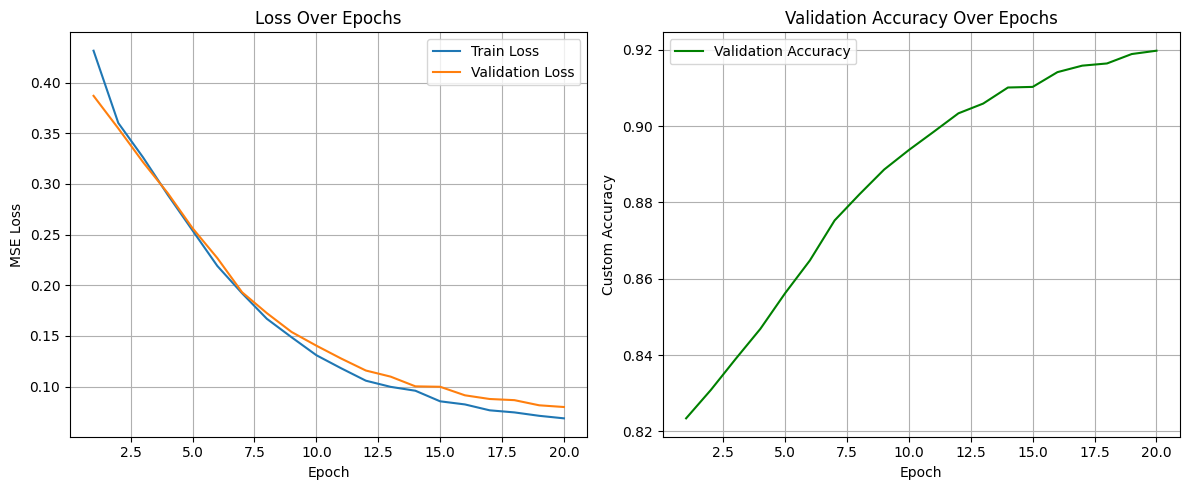

In [37]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Train Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Loss Over Epochs')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, val_accuracies, label='Validation Accuracy', color='green')
plt.xlabel('Epoch')
plt.ylabel('Custom Accuracy')
plt.title('Validation Accuracy Over Epochs')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Prediction Visualization

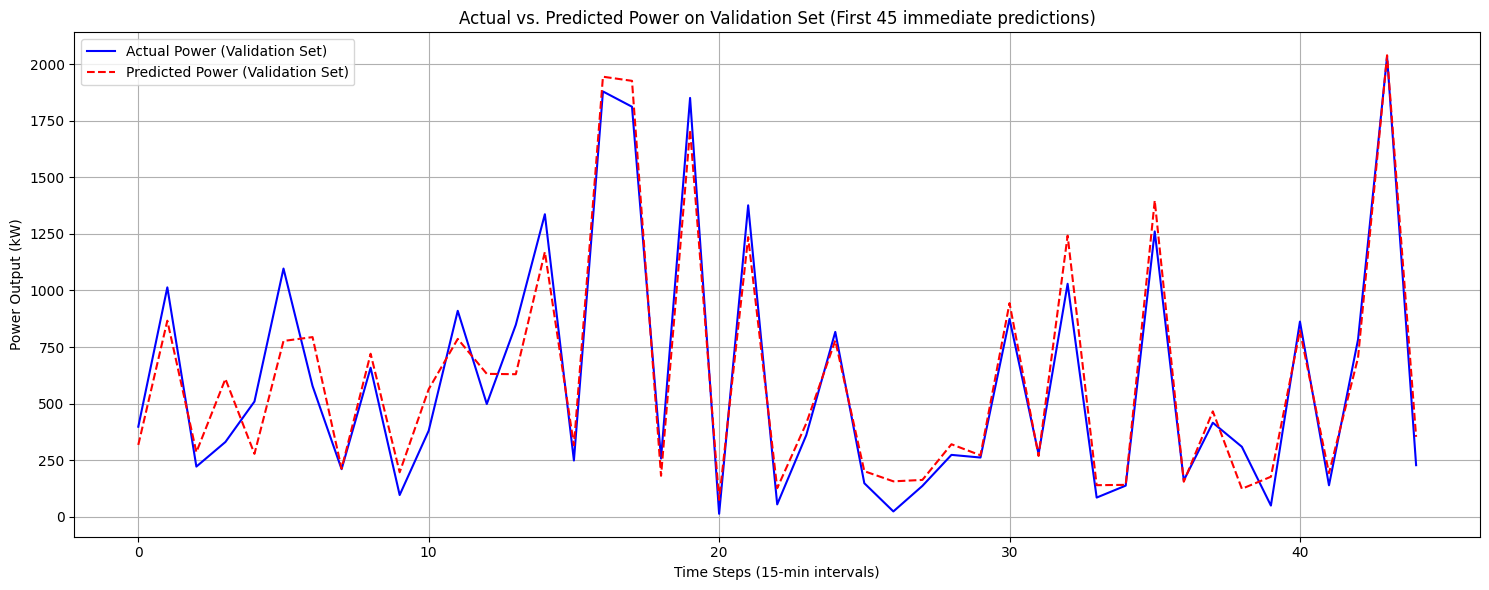

Shape of predicted_values: (7878, 16)
Shape of true_values: (7878, 16)
Length of predicted segment for plotting: 45
Length of true segment for plotting: 45


In [42]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Assuming the previous code for data loading, preprocessing,
# model definition, and training has been run.

# 1. Make Predictions on the Validation Set
def get_predictions(model, dataloader, scaler_y, device):
    model.eval()  # Set model to evaluation mode
    all_predictions = []
    all_true_values = []

    with torch.no_grad():  # Disable gradient calculation for inference
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)
            output = model(X_batch)

            # Inverse transform predictions and true values
            # Output shape: (batch_size, pred_len)
            # y_batch shape: (batch_size, pred_len, 1)
            predicted_power = scaler_y.inverse_transform(output.cpu().numpy())
            true_power = scaler_y.inverse_transform(y_batch.cpu().numpy().reshape(-1, 1)).reshape(y_batch.shape[0], y_batch.shape[1])

            all_predictions.append(predicted_power)
            all_true_values.append(true_power)

    return np.concatenate(all_predictions, axis=0), np.concatenate(all_true_values, axis=0)

# Get predictions for the validation set
device = "cuda" if torch.cuda.is_available() else "cpu"
predicted_values, true_values = get_predictions(trained_model, val_loader, scaler_y, device)

# 2. Select a Segment for Visualization
# Let's visualize the first 100 predictions from the validation set.
# Remember that each prediction is for 'pred_len' future steps.
# To plot a continuous series, we need to be careful with how we select.
# For simplicity, let's just take the first predicted step (0) from each sequence,
# and the first true step (0) from each sequence to get a single time series.

# Flatten the predictions and true values to plot them as continuous series
# We are taking the first predicted value of each sequence (index 0)
# and the first true value of each sequence (index 0) for visualization.
# This assumes we want to see the immediate next prediction.
segment_length = 45 # Adjust this to see a longer or shorter segment

# Ensure we don't go out of bounds
segment_length = min(segment_length, predicted_values.shape[0])

# Extract the first predicted step and first true step for the segment
# (assuming pred_len is the same for all, and we want to visualize the immediate next prediction)
predicted_segment = predicted_values[:segment_length, 0]
true_segment = true_values[:segment_length, 0]

# 3. Plot Actual vs. Predicted Power
plt.figure(figsize=(15, 6))
plt.plot(true_segment, label='Actual Power (Validation Set)', color='blue')
plt.plot(predicted_segment, label='Predicted Power (Validation Set)', color='red', linestyle='--')
plt.title(f'Actual vs. Predicted Power on Validation Set (First {segment_length} immediate predictions)')
plt.xlabel('Time Steps (15-min intervals)')
plt.ylabel('Power Output (kW)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Shape of predicted_values: {predicted_values.shape}")
print(f"Shape of true_values: {true_values.shape}")
print(f"Length of predicted segment for plotting: {len(predicted_segment)}")
print(f"Length of true segment for plotting: {len(true_segment)}")

Create a plot that specifically highlights the prediction horizon for a few selected sequences. Instead of just plotting the immediate next predicted step, this visualization will show the model's multi-step forecast (all pred_len steps) against the actual values for those future steps.

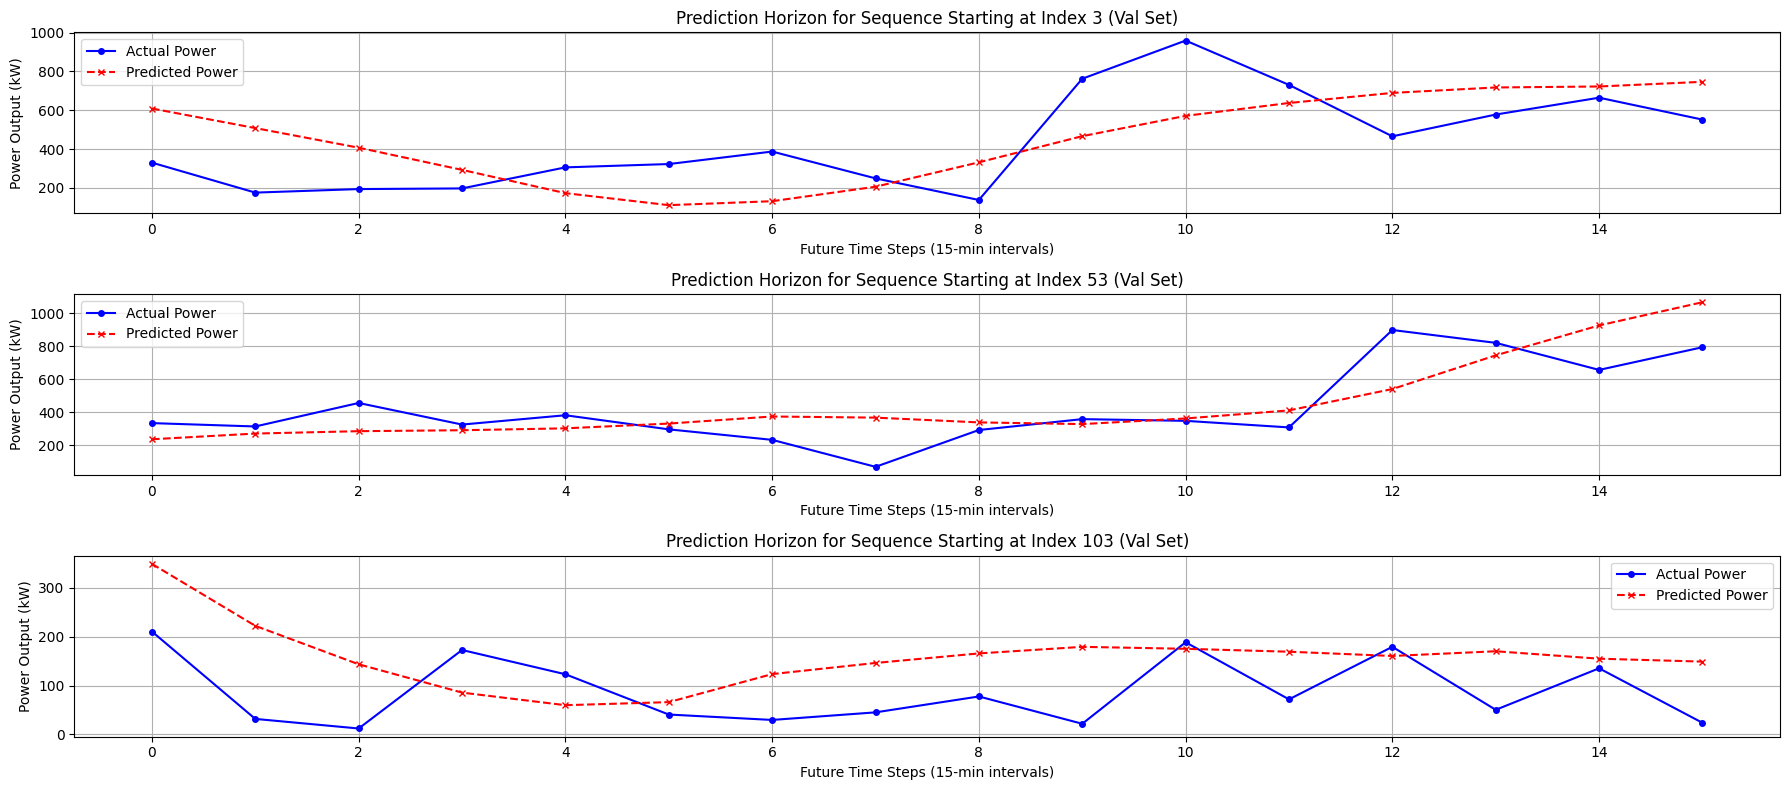

Visualizing 3 prediction horizons, each of length 16 steps.


In [44]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Assuming the previous code for data loading, preprocessing,
# model definition, and training has been run, and
# predicted_values, true_values, and val_loader are available.

# 1. Select specific indices from the validation set for detailed visualization
# Let's pick 3-5 example sequences to visualize their full prediction horizons.
# We need to ensure these indices are valid within the val_loader.

# For simplicity, let's just use the first few sequences from our predicted_values/true_values arrays
# as they correspond to sequences from the validation set.
num_examples_to_plot = 3 # You can change this to visualize more or fewer examples
start_indices_for_plot = [3, 53, 103] # Example starting indices from the validation set
                                    # (these correspond to the index in the flattened predicted_values array)

# Ensure indices are within bounds
start_indices_for_plot = [idx for idx in start_indices_for_plot if idx < predicted_values.shape[0]]

# Define the prediction length from our model setup
# (This should be the same as the 'pred_len' used when defining WindDataset and LSTMForecastModel)
# We can get it from the model itself or recall it from earlier
# pred_len = model.pred_len # If you store it in the model
pred_len = 16 # As defined in your previous script

# 2. Plot Actual vs. Multi-step Predicted Power for Selected Examples
plt.figure(figsize=(18, 8)) # Make the figure larger to accommodate multiple subplots or a wider view

for i, start_idx in enumerate(start_indices_for_plot):
    if start_idx + pred_len > predicted_values.shape[0]:
        print(f"Skipping index {start_idx} as it goes out of bounds for pred_len={pred_len}")
        continue

    # Actual values for the prediction horizon
    # true_values[start_idx] gives the true_values for the sequence starting at start_idx
    actual_horizon = true_values[start_idx, :pred_len]

    # Predicted values for the prediction horizon
    predicted_horizon = predicted_values[start_idx, :pred_len]

    plt.subplot(num_examples_to_plot, 1, i + 1) # Arrange plots vertically
    # Time steps for the horizon (e.g., 0, 1, ..., pred_len-1)
    time_steps = np.arange(pred_len)

    plt.plot(time_steps, actual_horizon, label='Actual Power', color='blue', marker='o', markersize=4)
    plt.plot(time_steps, predicted_horizon, label='Predicted Power', color='red', linestyle='--', marker='x', markersize=4)

    plt.title(f'Prediction Horizon for Sequence Starting at Index {start_idx} (Val Set)')
    plt.xlabel('Future Time Steps (15-min intervals)')
    plt.ylabel('Power Output (kW)')
    plt.legend()
    plt.grid(True)

plt.tight_layout() # Adjust layout to prevent overlapping
plt.show()

print(f"Visualizing {len(start_indices_for_plot)} prediction horizons, each of length {pred_len} steps.")

## Save the Trained Model and Scalers

In [46]:
import torch
import joblib # For saving scikit-learn scalers

# Save the trained model
torch.save(trained_model.state_dict(), 'lstm_wind_power_model.pth')
print("Trained model saved as lstm_wind_power_model.pth")

# Save the scalers
joblib.dump(scaler_x, 'scaler_x.pkl')
joblib.dump(scaler_y, 'scaler_y.pkl')
print("Scalers saved as scaler_x.pkl and scaler_y.pkl")

Trained model saved as lstm_wind_power_model.pth
Scalers saved as scaler_x.pkl and scaler_y.pkl


## Deploying as a Web Service (e.g., using Flask)

In [47]:
# import pandas as pd
# import numpy as np
# import torch
# import torch.nn as nn
# import joblib
# from flask import Flask, request, jsonify

# # --- Model and Scaler Loading ---
# # Define the LSTM-based forecasting model (MUST BE IDENTICAL TO TRAINING)
# class LSTMForecastModel(nn.Module):
#     def __init__(self, input_dim, hidden_dim, num_layers, pred_len):
#         super(LSTMForecastModel, self).__init__()
#         self.hidden_dim = hidden_dim
#         self.num_layers = num_layers
#         self.pred_len = pred_len

#         self.lstm = nn.LSTM(
#             input_size=input_dim,
#             hidden_size=hidden_dim,
#             num_layers=num_layers,
#             batch_first=True
#         )
#         self.fc = nn.Linear(hidden_dim, pred_len)

#     def forward(self, x):
#         out, _ = self.lstm(x)
#         last_hidden = out[:, -1, :]
#         prediction = self.fc(last_hidden)
#         return prediction

# # Load the trained model and scalers
# try:
#     # These dimensions should match what you used in training
#     # You might want to save these as well, or hardcode them if fixed
#     input_dim = 20 # Number of features used in X (from your features list)
#     hidden_dim = 128
#     num_layers = 2
#     pred_len = 16 # The prediction horizon

#     model = LSTMForecastModel(input_dim, hidden_dim, num_layers, pred_len)
#     model.load_state_dict(torch.load('lstm_wind_power_model.pth', map_location=torch.device('cpu')))
#     model.eval() # Set to evaluation mode
#     print("Model loaded successfully.")

#     scaler_x = joblib.load('scaler_x.pkl')
#     scaler_y = joblib.load('scaler_y.pkl')
#     print("Scalers loaded successfully.")

# except Exception as e:
#     print(f"Error loading model or scalers: {e}")
#     # Exit or handle gracefully if loading fails
#     exit()

# # Define features list (MUST BE IDENTICAL TO TRAINING)
# features = [
#     'wind_speed', 'wind_direction', 'cabin_angle', 'total_cabin_angle',
#     'paddle1_angle', 'paddle2_angle', 'paddle3_angle', 'outdoor_temp',
#     'wind_speed_100m', 'wind_direction_100m', 'temperature', 'air_pressure', 'air_density',
#     'hour', 'dayofweek', 'month',
#     'power_lag_1', 'power_lag_2', 'power_lag_3', 'power_lag_4'
# ]

# # --- Flask App Setup ---
# app = Flask(__name__)

# @app.route('/predict', methods=['POST'])
# def predict():
#     try:
#         data = request.get_json(force=True)
#         # data is expected to be a list of dictionaries,
#         # where each dictionary represents one time step of input features.
#         # It needs to be 'input_len' long.

#         # Convert input data to DataFrame for consistent processing
#         input_df = pd.DataFrame(data)

#         # Ensure correct order of features and convert to numpy array
#         # This assumes the input JSON contains all necessary features for 'input_len' steps
#         # and they are correctly ordered. For example, the JSON might contain
#         # 'wind_speed', 'wind_direction', etc., and also the 'power_lag_x' features.
#         # This is critical! If your 'power_lag_x' features are *derived*
#         # from previous predictions, your service needs to handle that.
#         # For simplicity here, we assume the input JSON provides *all* 'features'.

#         # If the web service is receiving *current* SCADA/NWP data,
#         # and needs to compute time-based and lag features internally,
#         # that logic would need to be implemented here.
#         # For a true sequential prediction service, you'd likely feed
#         # one new timestep, predict, then feed that prediction as a lag for the next.
#         # But for a single 'batch' prediction, the client must provide all features for 'input_len'.

#         if len(input_df) != model.lstm.input_size: # Check against input_len, not input_dim
#              # input_len was 16. input_dim is X.shape[1] = 20.
#              # The input_df should have input_len rows, each with input_dim columns.
#             raise ValueError(f"Input data must contain {model.lstm.input_size} time steps for prediction.")


#         # Ensure all required features are present and in the correct order
#         input_array = input_df[features].values

#         # Normalize the input features
#         scaled_input = scaler_x.transform(input_array)

#         # Convert to PyTorch tensor and reshape for the model
#         # The model expects (batch_size, input_len, input_dim)
#         input_tensor = torch.tensor(scaled_input, dtype=torch.float32).unsqueeze(0) # Add batch dimension

#         # Make prediction
#         with torch.no_grad():
#             raw_prediction = model(input_tensor)

#         # Inverse transform the prediction
#         # raw_prediction is (1, pred_len), inverse_transform expects (n_samples, n_features)
#         predicted_power_normalized = raw_prediction.cpu().numpy()
#         predicted_power = scaler_y.inverse_transform(predicted_power_normalized)

#         # Convert to list for JSON response
#         predicted_power_list = predicted_power[0].tolist() # Take the first (and only) batch prediction

#         return jsonify({'predicted_power_kW': predicted_power_list})

#     except Exception as e:
#         return jsonify({'error': str(e)}), 400

# if __name__ == '__main__':
#     app.run(debug=True, host='0.0.0.0', port=5000) # Run on all interfaces for Docker

In [ ]:
# requirements.txt
# flask
# pandas
# numpy
# torch
# scikit-learn
# joblib

In [48]:
# python app.py

In [49]:
# curl -X POST -H "Content-Type: application/json" \
#      -d '[
#           {"wind_speed": 5.0, "wind_direction": 180.0, "cabin_angle": 0.0, "total_cabin_angle": 0.0, "paddle1_angle": 10.0, "paddle2_angle": 10.0, "paddle3_angle": 10.0, "outdoor_temp": 15.0, "wind_speed_100m": 5.5, "wind_direction_100m": 185.0, "temperature": 16.0, "air_pressure": 1012.0, "air_density": 1.22, "hour": 10, "dayofweek": 2, "month": 7, "power_lag_1": 100.0, "power_lag_2": 95.0, "power_lag_3": 90.0, "power_lag_4": 85.0},
#           # ... 14 more similar dictionaries for input_len=16 ...
#           {"wind_speed": 5.1, "wind_direction": 181.0, "cabin_angle": 0.0, "total_cabin_angle": 0.0, "paddle1_angle": 10.1, "paddle2_angle": 10.1, "paddle3_angle": 10.1, "outdoor_temp": 15.1, "wind_speed_100m": 5.6, "wind_direction_100m": 186.0, "temperature": 16.1, "air_pressure": 1012.1, "air_density": 1.221, "hour": 10, "dayofweek": 2, "month": 7, "power_lag_1": 105.0, "power_lag_2": 100.0, "power_lag_3": 95.0, "power_lag_4": 90.0}
#         ]' \
#      http://127.0.0.1:5000/predict

## Containerize with Docker (Recommended for Deployment) 

In [50]:
# # Use an official Python runtime as a parent image
# FROM python:3.9-slim-buster

# # Set the working directory in the container
# WORKDIR /app

# # Copy the requirements file into the container
# COPY requirements.txt .

# # Install any needed packages specified in requirements.txt
# RUN pip install --no-cache-dir -r requirements.txt

# # Copy the trained model, scalers, and your application code into the container
# COPY lstm_wind_power_model.pth .
# COPY scaler_x.pkl .
# COPY scaler_y.pkl .
# COPY app.py .

# # Make port 5000 available to the world outside this container
# EXPOSE 5000

# # Run app.py when the container launches
# CMD ["flask", "run", "--host=0.0.0.0", "--port=5000"]

In [52]:
# docker build -t wind-power-predictor .

In [53]:
# docker run -p 5000:5000 wind-power-predictor